# Retail Case Study 고객 구매 패턴 분석과 RFM 고객 세분화

상품·고객·거래 데이터를 연결해 구매 패턴을 탐색하고 RFM으로 고객을 세분화한다. 전처리와 통계 로직은 `src/pipeline.py`의 `DataAnalyzer`에서 호출한다.

로컬에서 같은 분석을 실행하는 방법은 [README](../README.md)에 정리했다.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.pipeline import DataAnalyzer

DATA_DIR = Path(os.environ.get("RETAIL_DATA_DIR", PROJECT_ROOT / "data"))
RANDOM_SEED = 42
analyzer = DataAnalyzer(DATA_DIR)

## 1. 데이터 로드 및 기본 탐색

- `Transactions.csv`는 거래일, 고객 ID, 상품 서브카테고리 코드, 카테고리 코드, 수량, 단가, 세금, 거래 금액을 제공한다.
- `Customer.csv`는 고객 생년월일, 성별, 도시 코드를 제공한다.
- `prod_cat_info.csv`는 상품 카테고리명과 서브카테고리명을 제공한다.

거래 이력이 있는 고객 ID를 정렬한 뒤 고정 시드로 100명을 뽑고, 선택된 고객의 관측 기간 거래를 모두 보존한다.
반품에 해당하는 음수 거래 금액은 분석에서 제외한다.

In [2]:
transactions, customers, products = analyzer.load_data(
    sample_size=100, random_state=RANDOM_SEED
)
assert len(transactions) >= 100, "표본 거래가 100행 이상 필요합니다."

print("거래 표본:", transactions.shape)
print("고객 표본:", customers.shape)
print("상품 표본:", products.shape)

for table in (transactions, customers, products):
    display(table.head())
    table.info()

거래 표본: (390, 10)
고객 표본: (100, 5)
상품 표본: (23, 4)


,transaction_id,customer_id,tran_date,prod_subcat_code,prod_cat_code,Qty,Rate,Tax,total_amt,Store_type
40,90740728864,268229,2014-02-19,4,2,5,984,516.600,5436.600,TeleShop
80,55452156634,273734,2014-02-16,3,5,5,778,408.450,4298.450,e-Shop
199,80632003085,268801,2014-02-10,10,6,4,857,359.940,3787.940,e-Shop
220,86159101262,270240,2014-02-09,12,5,3,680,214.200,2254.200,e-Shop
327,6194846096,270044,2014-02-03,8,3,5,309,162.225,1707.225,Flagship store


<class 'pandas.core.frame.DataFrame'>
Index: 390 entries, 40 to 22960
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   transaction_id    390 non-null    int64         
 1   customer_id       390 non-null    string        
 2   tran_date         390 non-null    datetime64[ns]
 3   prod_subcat_code  390 non-null    string        
 4   prod_cat_code     390 non-null    string        
 5   Qty               390 non-null    int64         
 6   Rate              390 non-null    int64         
 7   Tax               390 non-null    float64       
 8   total_amt         390 non-null    float64       
 9   Store_type        390 non-null    object        
dtypes: datetime64[ns](1), float64(2), int64(3), object(1), string(3)
memory usage: 33.5+ KB


,customer_id,DOB,Gender,city_code,age
77,269271,1970-05-12,F,5.0,43.8
116,273442,1970-07-16,M,4.0,43.6
123,273575,1970-07-27,M,1.0,43.6
226,270768,1970-12-27,M,10.0,43.1
309,272037,1971-04-29,F,7.0,42.8


<class 'pandas.core.frame.DataFrame'>
Index: 100 entries, 77 to 5604
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   customer_id  100 non-null    string        
 1   DOB          100 non-null    datetime64[ns]
 2   Gender       100 non-null    object        
 3   city_code    100 non-null    float64       
 4   age          100 non-null    float64       
dtypes: datetime64[ns](1), float64(2), object(1), string(1)
memory usage: 4.7+ KB


,prod_cat_code,prod_cat,prod_subcat_code,prod_subcat
0,1,Clothing,4,Mens
1,1,Clothing,1,Women
2,1,Clothing,3,Kids
3,2,Footwear,1,Mens
4,2,Footwear,3,Women


<class 'pandas.core.frame.DataFrame'>
Index: 23 entries, 0 to 22
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   prod_cat_code     23 non-null     string
 1   prod_cat          23 non-null     object
 2   prod_subcat_code  23 non-null     string
 3   prod_subcat       23 non-null     object
dtypes: object(2), string(2)
memory usage: 920.0+ bytes


## 2. 결측치 처리와 데이터 병합

성별(`Gender`)이 비어 있으면 `Unknown`으로 표시한다. 고객 나이는 생년월일(`DOB`)에서 기준일 기준으로 계산하며, 생년월일이 없는 경우 성별 그룹의 중앙값으로 대치하고 남은 값에는 전체 중앙값을 사용한다.

거래를 기준으로 상품과 고객 정보를 연결한다.

In [3]:
display(products.isna().sum())
display(customers.isna().sum())
display(transactions.isna().sum())

prod_cat_code       0
prod_cat            0
prod_subcat_code    0
prod_subcat         0
dtype: int64

customer_id    0
DOB            0
Gender         0
city_code      0
age            0
dtype: int64

transaction_id      0
customer_id         0
tran_date           0
prod_subcat_code    0
prod_cat_code       0
Qty                 0
Rate                0
Tax                 0
total_amt           0
Store_type          0
dtype: int64

In [4]:
customers["Gender"] = customers["Gender"].fillna("Unknown")
customers["age"] = analyzer.handle_missing_values(
    customers, "age", group_col="Gender", strategy="median"
)

customers.isna().sum()

customer_id    0
DOB            0
Gender         0
city_code      0
age            0
dtype: int64

In [5]:
df = transactions.merge(
    products,
    left_on=["prod_cat_code", "prod_subcat_code"],
    right_on=["prod_cat_code", "prod_subcat_code"],
    how="left",
)

df = df.merge(
    customers,
    on="customer_id",
    how="left",
)

print(df.shape)
display(df.head())

df.isna().sum()

(390, 16)


,transaction_id,customer_id,tran_date,prod_subcat_code,prod_cat_code,Qty,Rate,Tax,total_amt,Store_type,prod_cat,prod_subcat,DOB,Gender,city_code,age
0,90740728864,268229,2014-02-19,4,2,5,984,516.600,5436.600,TeleShop,Footwear,Kids,1989-03-01,F,3.0,25.0
1,55452156634,273734,2014-02-16,3,5,5,778,408.450,4298.450,e-Shop,Books,Comics,1987-11-07,F,9.0,26.3
2,80632003085,268801,2014-02-10,10,6,4,857,359.940,3787.940,e-Shop,Home and kitchen,Kitchen,1977-01-04,M,7.0,37.1
3,86159101262,270240,2014-02-09,12,5,3,680,214.200,2254.200,e-Shop,Books,Academic,1988-12-07,M,1.0,25.2
4,6194846096,270044,2014-02-03,8,3,5,309,162.225,1707.225,Flagship store,Electronics,Personal Appliances,1985-02-12,M,6.0,29.0


transaction_id      0
customer_id         0
tran_date           0
prod_subcat_code    0
prod_cat_code       0
Qty                 0
Rate                0
Tax                 0
total_amt           0
Store_type          0
prod_cat            0
prod_subcat         0
DOB                 0
Gender              0
city_code           0
age                 0
dtype: int64

## 3. 텍스트 피처 생성

서브카테고리명(`prod_subcat`)의 문자 수를 계산해 `product_name_length` 컬럼을 추가한다.
공백과 숫자, 특수문자도 문자 수에 포함한다.

In [6]:
df = analyzer.add_text_features(df)

display(
    df[["prod_subcat_code", "prod_subcat", "product_name_length"]].head()
)

,prod_subcat_code,prod_subcat,product_name_length
0,4,Kids,4
1,3,Comics,6
2,10,Kitchen,7
3,12,Academic,8
4,8,Personal Appliances,19


In [7]:
display(
    df.drop_duplicates("prod_subcat_code")["product_name_length"].describe()
)

count    12.000000
mean      7.416667
std       4.209477
min       3.000000
25%       4.750000
50%       7.000000
75%       8.250000
max      19.000000
Name: product_name_length, dtype: float64

## 4. IQR 기반 거래 금액 이상치 탐지

IQR은 제3사분위수(Q3)와 제1사분위수(Q1)의 차이다.

- 하한: Q1 - 1.5 × IQR
- 상한: Q3 + 1.5 × IQR

범위 밖의 거래 금액을 이상치 후보로 표시한다.
고가 구매도 정상 거래일 수 있으므로 거래를 삭제하지 않고,
이상치 후보를 제외했을 때의 분포를 비교한다.

In [8]:
df["amount_outlier"] = analyzer.detect_outliers(df["total_amt"], threshold=1.5)

print("전체 거래 수:", len(df))
print("이상치 후보 수:", df["amount_outlier"].sum())
print(
    "이상치 후보 비율:",
    round(df["amount_outlier"].mean() * 100, 2),
    "%",
)

전체 거래 수: 390
이상치 후보 수: 9
이상치 후보 비율: 2.31 %


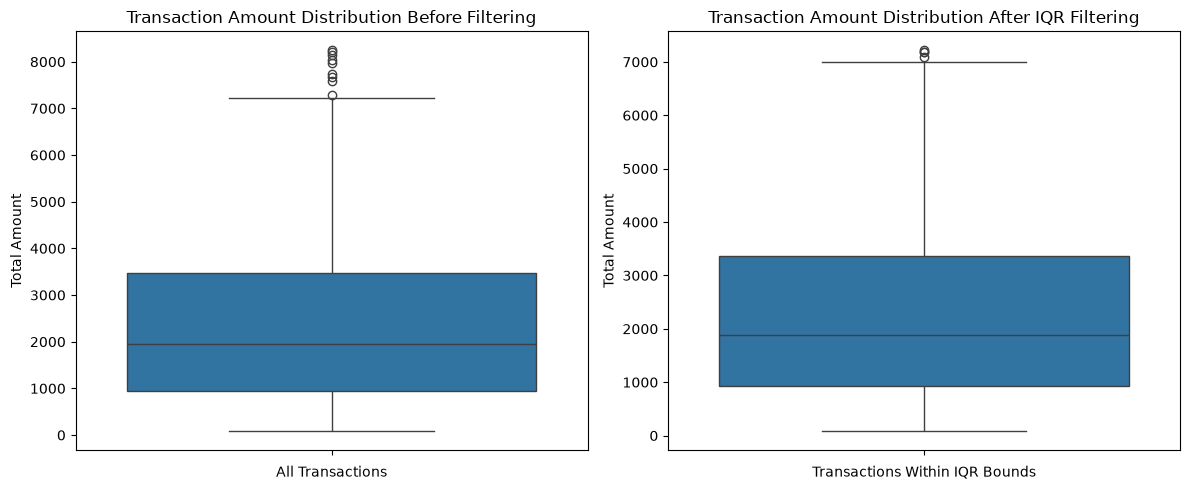

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df["total_amt"], ax=axes[0])
axes[0].set_title("Transaction Amount Distribution Before Filtering")
axes[0].set_xlabel("All Transactions")
axes[0].set_ylabel("Total Amount")

sns.boxplot(
    y=df.loc[~df["amount_outlier"], "total_amt"],
    ax=axes[1],
)
axes[1].set_title("Transaction Amount Distribution After IQR Filtering")
axes[1].set_xlabel("Transactions Within IQR Bounds")
axes[1].set_ylabel("Total Amount")

plt.tight_layout()
plt.show()

## 5. 인구통계 피처 분석

고객의 성별(`Gender`)과 도시 코드(`city_code`)별 구매 패턴을 분석한다.

- `Gender`: 성별에 따른 구매 빈도와 평균 거래 금액 비교
- `city_code`: 지역별 고객 분포와 평균 구매 금액 비교

고객 1인당 통계를 계산해 거래 수가 많은 고객의 중복 반영을 막는다.

In [10]:
gender_stats = (
    df.groupby(["customer_id", "Gender"])
    .agg(total_spent=("total_amt", "sum"), purchase_days=("tran_date", "nunique"))
    .reset_index()
    .groupby("Gender")
    .agg(
        customer_count=("customer_id", "count"),
        avg_total_spent=("total_spent", "mean"),
        avg_purchase_days=("purchase_days", "mean"),
    )
    .round(2)
)

display(gender_stats)

,customer_count,avg_total_spent,avg_purchase_days
Gender,,,
F,51,10034.22,4.02
M,49,9095.64,3.76


In [11]:
city_stats = (
    df.groupby(["customer_id", "city_code"])
    .agg(total_spent=("total_amt", "sum"))
    .reset_index()
    .groupby("city_code")
    .agg(
        customer_count=("customer_id", "count"),
        avg_total_spent=("total_spent", "mean"),
    )
    .round(2)
    .sort_values("customer_count", ascending=False)
)

display(city_stats)

,customer_count,avg_total_spent
city_code,,
6.0,15,6506.61
10.0,14,9781.38
1.0,13,12133.16
7.0,12,9509.08
4.0,11,7904.67
3.0,10,11331.33
8.0,9,6847.32
5.0,6,12649.86
9.0,6,11891.09


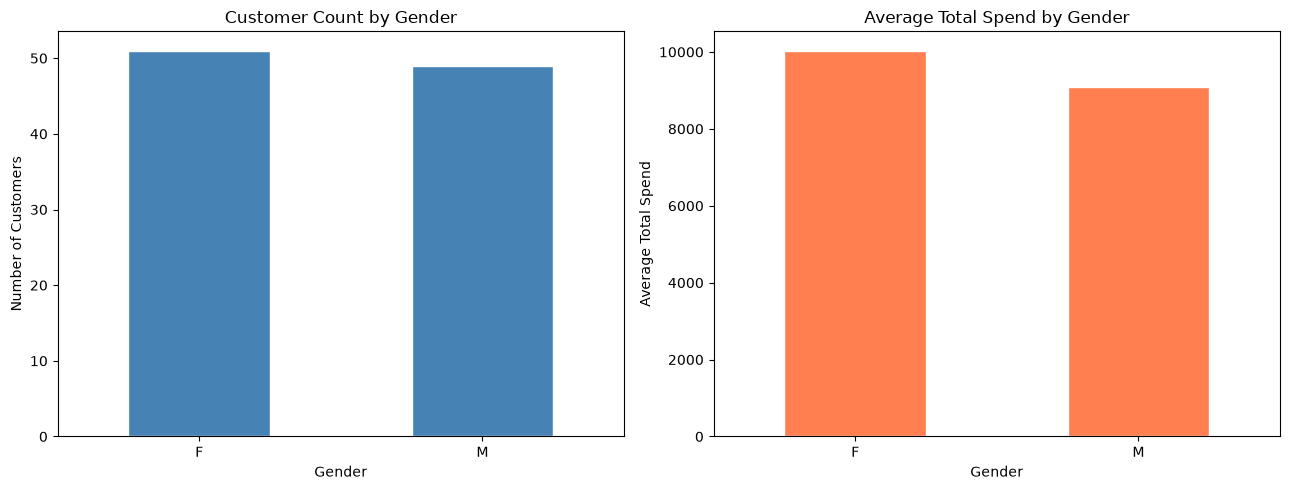

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

gender_stats["customer_count"].plot(
    kind="bar", ax=axes[0], color="steelblue", edgecolor="white"
)
axes[0].set_title("Customer Count by Gender")
axes[0].set_xlabel("Gender")
axes[0].set_ylabel("Number of Customers")
axes[0].tick_params(axis="x", rotation=0)

gender_stats["avg_total_spent"].plot(
    kind="bar", ax=axes[1], color="coral", edgecolor="white"
)
axes[1].set_title("Average Total Spend by Gender")
axes[1].set_xlabel("Gender")
axes[1].set_ylabel("Average Total Spend")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

## 6. 통계 분석

거래 금액, 수량, 상품명 길이의 분포를 확인하고,
변수 간 피어슨 상관계수를 계산한다.

거래 데이터를 기준으로 계산하므로 여러 번 구매된 상품은 반복 반영된다.
상관관계는 인과관계를 의미하지 않는다.

In [13]:
display(
    analyzer.summarize(
        df, ["total_amt", "Qty", "product_name_length"]
    ).round(4)
)

,total_amt,Qty,product_name_length
count,390.0000,390.0000,390.0000
mean,2454.9530,2.9897,7.0359
std,1881.2613,1.4501,3.9141
min,79.5600,1.0000,3.0000
25%,951.1288,2.0000,4.0000
50%,1950.3250,3.0000,6.0000
75%,3480.1975,4.0000,8.0000
max,8243.3000,5.0000,19.0000


In [14]:
print(
    "거래 금액과 수량의 상관계수:",
    round(df["total_amt"].corr(df["Qty"]), 4),
)

print(
    "거래 금액과 상품명 길이의 상관계수:",
    round(df["total_amt"].corr(df["product_name_length"]), 4),
)

거래 금액과 수량의 상관계수: 0.6395
거래 금액과 상품명 길이의 상관계수: -0.1049


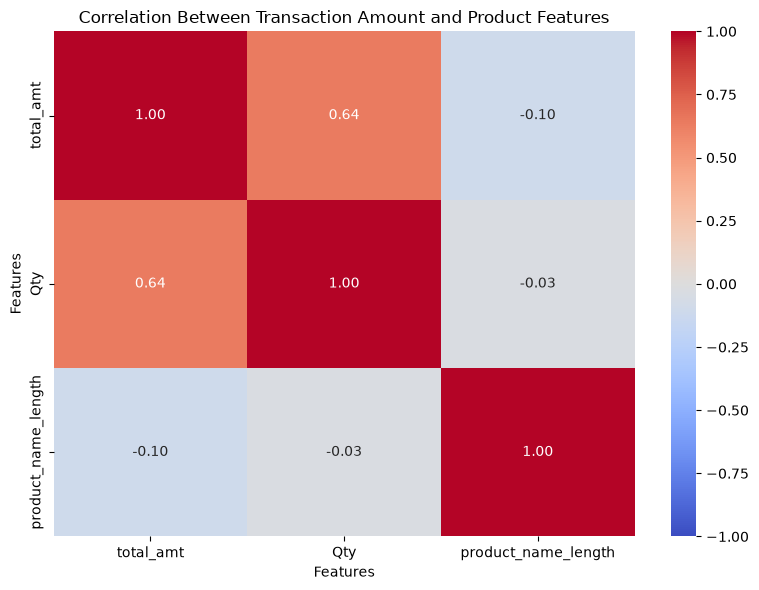

In [15]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    df[["total_amt", "Qty", "product_name_length"]].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
)

plt.title("Correlation Between Transaction Amount and Product Features")
plt.xlabel("Features")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

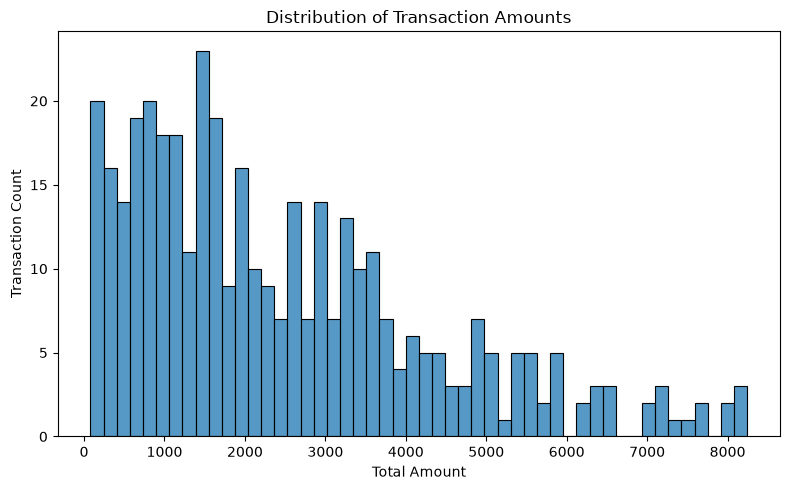

In [16]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="total_amt", bins=50)

plt.title("Distribution of Transaction Amounts")
plt.xlabel("Total Amount")
plt.ylabel("Transaction Count")
plt.tight_layout()
plt.show()

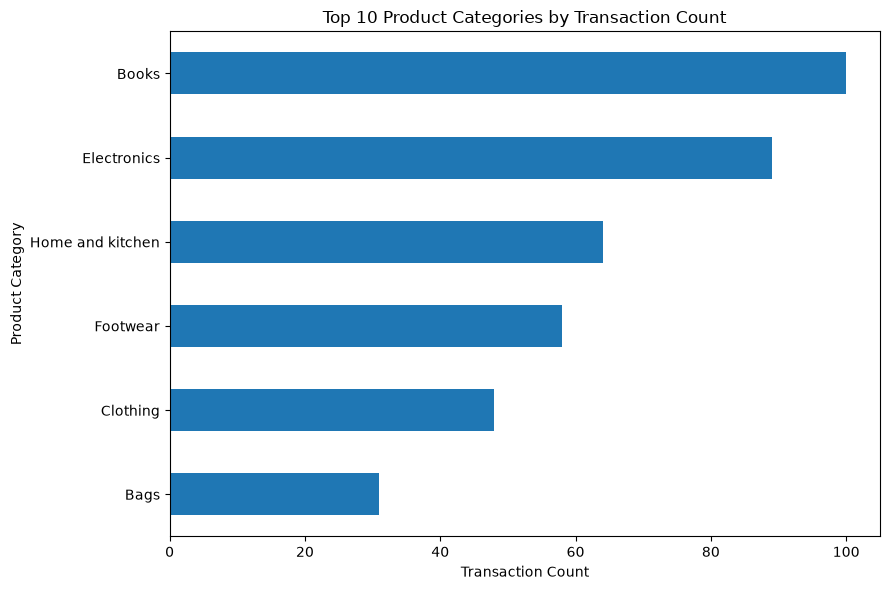

In [17]:
df["prod_cat"].value_counts().head(10).sort_values().plot(
    kind="barh",
    figsize=(9, 6),
)

plt.title("Top 10 Product Categories by Transaction Count")
plt.xlabel("Transaction Count")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

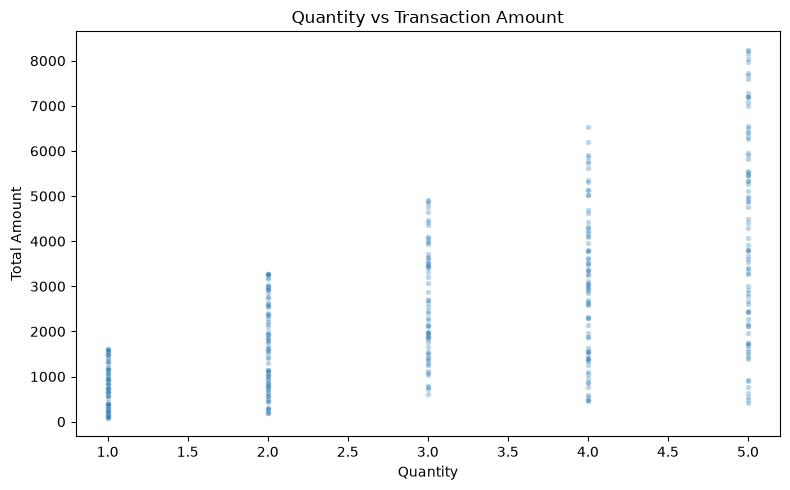

In [18]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Qty",
    y="total_amt",
    alpha=0.3,
    s=15,
)

plt.title("Quantity vs Transaction Amount")
plt.xlabel("Quantity")
plt.ylabel("Total Amount")
plt.tight_layout()
plt.show()

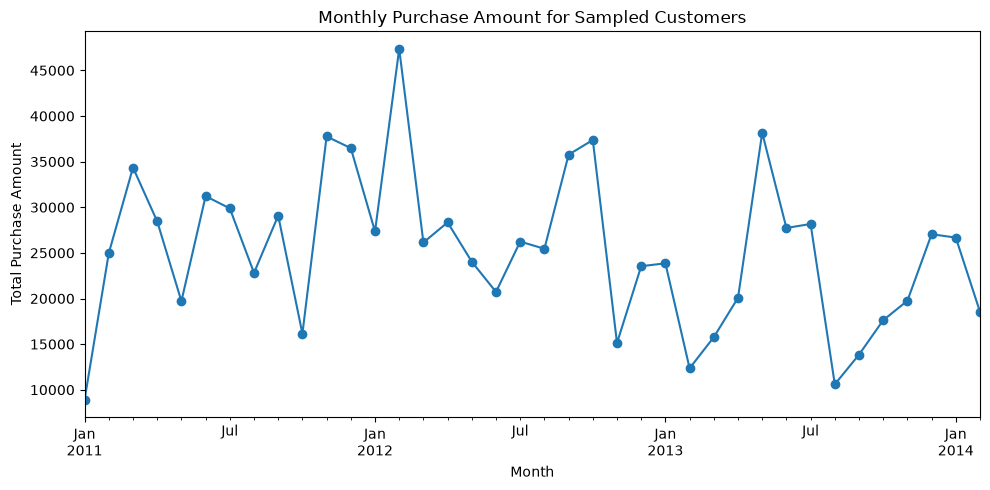

In [19]:
df.resample(
    "MS",
    on="tran_date",
)["total_amt"].sum().plot(
    figsize=(10, 5),
    marker="o",
)

plt.title("Monthly Purchase Amount for Sampled Customers")
plt.xlabel("Month")
plt.ylabel("Total Purchase Amount")
plt.tight_layout()
plt.show()

## 7. RFM 고객 분석

분석 기준일은 표본 거래 데이터의 최종 거래일로 설정한다.

- Recency: 분석 기준일부터 마지막 구매일까지의 경과 일수
- Frequency: 고객별 서로 다른 구매 날짜 수
- Monetary: 고객별 거래 금액의 합계

이상치 후보와 동일한 거래 행도 유지한다.
고가 구매 및 대량 구매가 고객 구매금액에 반영되도록 한다.

In [20]:
reference_date = df["tran_date"].max()

print("분석 기준일:", reference_date)

분석 기준일: 2014-02-19 00:00:00


In [21]:
rfm = analyzer.calculate_rfm(df, reference_date=reference_date)

print("RFM 고객 수:", len(rfm))
display(rfm.head())

RFM 고객 수: 100


,recency,frequency,monetary
customer_id,,,
266805,54,1,4623.320
266836,739,4,11082.045
266901,88,4,8327.280
267156,70,3,11161.605
267230,122,3,4657.575


In [22]:
display(rfm.describe().round(2))

,recency,frequency,monetary
count,100.00,100.00,100.00
mean,295.80,3.89,9574.32
std,253.08,1.73,5840.75
min,0.00,1.00,209.95
25%,90.75,3.00,4649.01
50%,239.00,4.00,8992.49
75%,416.25,5.00,13057.51
max,1074.00,8.00,25775.23


## 8. RFM 점수와 고객 세분화

각 지표의 상대적 순위를 기준으로 1~5점을 부여한다.

- Recency: 경과 일수가 짧을수록 높은 점수
- Frequency: 구매 날짜 수가 많을수록 높은 점수
- Monetary: 구매금액 합계가 클수록 높은 점수

동일한 값에는 동일한 점수를 부여한다.
따라서 점수별 고객 수가 정확히 같지는 않을 수 있다.

In [23]:
rfm["r_score"] = np.ceil(
    rfm["recency"].rank(ascending=False, pct=True) * 5
).astype(int)

rfm["f_score"] = np.ceil(
    rfm["frequency"].rank(pct=True) * 5
).astype(int)

rfm["m_score"] = np.ceil(
    rfm["monetary"].rank(pct=True) * 5
).astype(int)

display(rfm.head())

,recency,frequency,monetary,r_score,f_score,m_score
customer_id,,,,,,
266805,54,1,4623.320,5,1,2
266836,739,4,11082.045,1,3,3
266901,88,4,8327.280,4,3,3
267156,70,3,11161.605,5,2,4
267230,122,3,4657.575,4,2,2


### RFM 세그먼트 분류 기준

고객별 최근성(R), 구매 빈도(F), 구매 금액(M)의 상대 순위를 1점부터 5점으로 환산한다. 마지막 구매가 최근일수록 R, 구매일 수가 많을수록 F, 거래 금액 합계가 클수록 M 점수가 높다. 순위 비율에 5를 곱해 올림하므로 4점과 5점은 상위 약 40%에 해당한다. 동점에는 평균 순위를 적용하므로 실제 비율은 달라질 수 있다.

| 우선순위 | 세그먼트 | 분류 조건 | 기준을 둔 이유 |
| --- | --- | --- | --- |
| 1 | VIP | `R ≥ 4`, `F ≥ 4`, `M ≥ 4` | 최근에 구매했고, 자주 구매하고, 구매 금액도 높은 고객 |
| 2 | Loyal | `R ≥ 3`, `F ≥ 4` | 최근성 기준을 완화하고 반복 구매를 중심으로 분류 |
| 3 | New | `R ≥ 4`, `frequency == 1` | 최근에 구매했고 관측 기간에 구매한 날짜가 하루인 고객 |
| 4 | At Risk | `R ≤ 2` | 마지막 구매가 표본 내에서 상대적으로 오래된 고객 |
| 5 | Regular | 앞선 조건 중 충족한 조건이 없음 | 기본 분류 |

In [24]:
rfm["segment"] = np.select(
    [
        (rfm["r_score"] >= 4)
        & (rfm["f_score"] >= 4)
        & (rfm["m_score"] >= 4),

        (rfm["r_score"] >= 3)
        & (rfm["f_score"] >= 4),

        (rfm["r_score"] >= 4)
        & (rfm["frequency"] == 1),

        rfm["r_score"] <= 2,
    ],
    [
        "VIP",
        "Loyal",
        "New",
        "At Risk",
    ],
    default="Regular",
)

display(rfm["segment"].value_counts())
print("세그먼트 수:", rfm["segment"].nunique())

segment
At Risk    40
Regular    35
VIP        14
Loyal       9
New         2
Name: count, dtype: int64

세그먼트 수: 5


In [25]:
seg_summary = (
    rfm.groupby("segment")
    .agg(
        customer_count=("monetary", "size"),
        avg_recency=("recency", "mean"),
        avg_frequency=("frequency", "mean"),
        avg_monetary=("monetary", "mean"),
        total_monetary=("monetary", "sum"),
    )
    .round(4)
)

seg_summary["monetary_pct"] = (
    seg_summary["total_monetary"] / seg_summary["total_monetary"].sum() * 100
).round(2)

display(seg_summary)

,customer_count,avg_recency,avg_frequency,avg_monetary,total_monetary,monetary_pct
segment,,,,,,
At Risk,40,544.9750,3.2250,7609.1958,304367.830,31.79
Loyal,9,198.8889,6.0000,13531.9528,121787.575,12.72
New,2,31.5000,1.0000,4205.6300,8411.260,0.88
Regular,35,146.4286,3.3429,8353.4211,292369.740,30.54
VIP,14,57.3571,6.2143,16463.9475,230495.265,24.07


## 9. 비즈니스 인사이트

### 분석 범위

고정 시드(42)로 뽑은 고객 100명의 거래를 분석했다. RFM 기준일은 표본의 마지막 거래일이다. Frequency는 서로 다른 구매 날짜 수이고, Monetary는 거래 금액의 합계다. 금액 비중은 세그먼트별 합계를 기준으로 계산했다.

### 1. VIP 고객 유지

VIP 고객은 최근에 구매했고 구매 빈도와 금액이 모두 높다. VIP가 전체 구매금액에서 차지하는 비중을 확인하고, 선호 카테고리의 신상품이나 프로모션을 안내해 재구매를 유도한다. VIP 내 대조군을 두고 동일 기간의 재구매율과 고객당 구매금액을 비교한다.

### 2. At Risk 고객 중 재활성화 대상 선별

At Risk는 마지막 구매가 상대적으로 오래된 고객이다. 과거 구매금액과 평소 구매 간격을 함께 보고 연락할 고객을 좁혀 재구매를 유도한다. 선별된 고객의 후속 구매율을 대조군과 비교한다.

### 3. Loyal과 Regular의 다음 구매 유도

Loyal은 반복 구매 빈도가 높은 고객이다. Loyal에는 반복 구매한 카테고리의 후속 상품을, Regular에는 관심 상품과 함께 구매할 만한 상품을 안내해 구매일 수 증가를 목표로 한다. 세그먼트마다 대조군을 두고 후속 구매일 수를 비교한다.

### 4. New 고객의 두 번째 구매일 관찰

New 고객은 최근에 구매했으나 관측 기간 내 구매일이 하루인 고객이다. 더 큰 표본에서 후속 기간에 두 번째 구매일이 생긴 고객 비율을 비교하고, 초기 구매 카테고리와 연계된 추천을 시험한다.

### 보조 분석. 거래 금액 분포와 인구통계

IQR 기준을 벗어난 거래 금액을 이상치 후보로 표시해 분포를 비교했고, RFM에는 전체 거래를 사용했다. 성별과 도시 코드별 평균 구매금액 차이는 세그먼트 분류와 함께 보면 고객군의 특성을 추가로 설명할 수 있다.